# Groundwater Feature Integration — Historical Crops (Lag-1)

**Objective:** Combine groundwater nitrate measurements with soil, terrain, climate, and historical agricultural features into a single table for machine learning.

**Procedure**
- The cleaned groundwater dataset is the starting point: **5,280 nitrate measurements from 1,993 wells** sampled 2022–2025 (`notebooks/data_cleaning/groundwater/gwater_clean.ipynb`).
- **Soil (SSURGO)** and **terrain (10 m DEM)** features are static and joined by well ID.
- **PRISM climate** features are matched to each sample, using only complete months before the sample date.
- **Historical crop features** (DWR crop maps, 500 m and 1,000 m buffers) are joined by well ID and the year *before* each nitrate measurement (lag-1; e.g., nitrate from 2023 uses the 2022 crop map).
- All joins are left joins that preserve every groundwater observation, and each join is checked for duplicated or unmatched rows.

**Output:** `notebooks/merge/groundwater_ml_integration_lag1_2021_2024_with_climate.csv` (5,280 rows × 147 columns), read by `src/features/preprocessing.py` (`load_model_data()`).

**Local-only inputs** (not tracked by Git; place them at these paths): `data/soils/soils_huc8_attributes.gpkg` and `data/elevation/dem_watershed_10m.tif`.

In [1]:
from pathlib import Path
import sys
PROJECT_ROOT = None
for folder in [Path.cwd(), *Path.cwd().parents]:
    if (folder / '.git').exists() and (folder / 'notebooks').is_dir():
        PROJECT_ROOT = folder
        break
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook from the project repository.")

import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.mask import mask
from shapely.geometry import mapping
import fiona

GROUNDWATER = PROJECT_ROOT / "notebooks" / "data_cleaning" / "groundwater"
CLIMATE = PROJECT_ROOT / "notebooks" / "data_cleaning" / "precipitation"
NITRATE_PATH = GROUNDWATER / "groundwater_nitrate_clean.csv"
BUFFER_PATH = GROUNDWATER / "groundwater_well_buffers_500m.gpkg"
SOIL_PATH = PROJECT_ROOT / 'data' / 'soils' / 'soils_huc8_attributes.gpkg'
DEM_PATH = PROJECT_ROOT / 'data' / 'elevation' / 'dem_watershed_10m.tif'
PRISM_PATH = CLIMATE / "prism_climate_monthly_clean.csv"
CROP_PATH = PROJECT_ROOT / "notebooks" / "data_cleaning" / "crop_mapping" / "crop_features_lag1_2021_2024.csv"

METRIC_CRS = "EPSG:3310"

def checked_left_merge(base, features, key, feature_name):
    """Left-join features while preserving the base rows and their order."""
    if key not in base.columns or key not in features.columns:
        raise KeyError(f"{feature_name}: missing join key {key!r}.")
    if features[key].duplicated().any():
        raise ValueError(f"{feature_name}: feature keys are not unique.")

    original_ids = base["observation_id"].copy()
    original_rows = len(base)
    merged = base.merge(
        features,
        on=key,
        how="left",
        validate="many_to_one",
        sort=False,
        indicator="_feature_match",
    )
    if len(merged) != original_rows or not merged["observation_id"].equals(original_ids):
        raise AssertionError(f"{feature_name}: merge changed base rows or order.")

    matched = int(merged["_feature_match"].eq("both").sum())
    coverage = {
        "feature": feature_name,
        "matched_rows": matched,
        "unmatched_rows": original_rows - matched,
        "missing_fraction": (original_rows - matched) / original_rows,
    }
    return merged.drop(columns="_feature_match"), coverage


## 1. Check the inputs

The checks stop if a required file or column is missing. That keeps an unavailable feature from being silently skipped.

In [2]:
required_paths = [NITRATE_PATH, BUFFER_PATH, SOIL_PATH, DEM_PATH, PRISM_PATH, CROP_PATH]
missing_paths = [path for path in required_paths if not path.exists()]
if missing_paths:
    raise FileNotFoundError("Missing inputs:\n" + "\n".join(map(str, missing_paths)))

observations = pd.read_csv(
    NITRATE_PATH,
    dtype={"gm_well_id": "string", "src_samp_collection_time": "string"},
    parse_dates=["gm_samp_collection_date"],
)
required = {"gm_well_id", "gm_samp_collection_date", "nitrate_mg_L", "gm_latitude", "gm_longitude"}
if not required.issubset(observations.columns):
    raise ValueError(f"Missing nitrate columns: {required - set(observations.columns)}")
if observations.empty:
    raise ValueError("The nitrate table is empty.")
sample_years = observations["gm_samp_collection_date"].dt.year
if not sample_years.between(2022, 2025).all():
    raise ValueError("Expected Charlsey's filtered nitrate data from 2022 through 2025.")
expected_rows = len(observations)
if observations[["gm_well_id", "gm_samp_collection_date"]].isna().any().any():
    raise ValueError("The nitrate table has a missing well ID or sample date.")

observations = observations.copy()
# The canonical CSV row number distinguishes repeated measurements.
observations["source_csv_row"] = observations.index + 2
observations["observation_id"] = "GW-CSV-" + observations["source_csv_row"].astype(str).str.zfill(5)
if observations["observation_id"].duplicated().any():
    raise ValueError("Observation IDs must be unique.")
base_ids = observations["observation_id"].copy()
print("Nitrate rows:", len(observations))
print("Unique wells:", observations.gm_well_id.nunique())
print("Years:", observations.gm_samp_collection_date.dt.year.min(),
      "to", observations.gm_samp_collection_date.dt.year.max())
print("Columns:", observations.columns.tolist())

Nitrate rows: 5280
Unique wells: 1993
Years: 2022 to 2025
Columns: ['gm_well_id', 'gm_well_category', 'gm_samp_collection_date', 'gm_latitude', 'gm_longitude', 'nitrate_mg_L', 'year', 'source_csv_row', 'observation_id']


## 2. Area-weighted SSURGO features

Existing 500 m buffers are overlaid with SSURGO polygons. Numeric values are averaged by intersected area. Category percentages use mapped category area; coverage percentages show how much of the full buffer is mapped. An absent category is 0 when category data are mapped, while no category coverage remains missing. No minimum coverage cutoff is assumed.

In [3]:
import shapely
buffers = gpd.read_file(BUFFER_PATH)
soils = gpd.read_file(SOIL_PATH)

if buffers.crs is None or soils.crs is None:
    raise ValueError("Both buffer and soil layers need a CRS.")
if buffers.empty:
    raise ValueError("The well buffer layer is empty.")
if buffers.gm_well_id.duplicated().any():
    raise ValueError("Expected one existing buffer per well ID.")

# Check geometries before reprojection or spatial operations. Invalid
# geometries are reported rather than silently repaired.
def check_geometries(frame, layer_name, id_column=None):
    missing = frame.geometry.isna()
    empty = frame.geometry.is_empty
    invalid = ~frame.geometry.is_valid
    problem = missing | empty | invalid

    if problem.any():
        examples = frame.loc[problem, id_column].head(10).tolist() if id_column else frame.index[problem].tolist()[:10]
        raise ValueError(
            f"{layer_name} has {int(problem.sum())} missing, empty, or invalid "
            f"geometries. Examples: {examples}"
        )

    print(f"{layer_name}: all {len(frame)} geometries are valid.")

check_geometries(buffers, "Buffers", "gm_well_id")
check_geometries(soils, "SSURGO soils")

soil_columns = ["slopegradwta", "brockdepmin", "aws0150wta", "drclassdcd", "hydgrpdcd"]
if not set(soil_columns).issubset(soils.columns):
    raise ValueError(f"Missing soil columns: {set(soil_columns) - set(soils.columns)}")

category_fields = ["drclassdcd", "hydgrpdcd"]
category_values = {}
for name in category_fields:
    category_values[name] = sorted(soils[name].dropna().unique(), key=str)

# Area calculations use the same metric CRS for both layers.
buffers = buffers.to_crs("EPSG:3310")
soils = soils.to_crs("EPSG:3310").reset_index(drop=True)

numeric_fields = ["slopegradwta", "brockdepmin", "aws0150wta"]
for name in numeric_fields:
    soils[name] = pd.to_numeric(soils[name], errors="coerce")

soil_features_by_batch = []
batch_size = 100
total_buffers = len(buffers)

for batch_start in range(0, total_buffers, batch_size):
    batch_end = min(batch_start + batch_size, total_buffers)
    batch = buffers.iloc[batch_start:batch_end][["gm_well_id", "geometry"]]

    # Find only soil polygons touching each buffer, then intersect all pairs
    # in one vectorized Shapely operation for this batch.
    candidates = gpd.sjoin(
        batch,
        soils[soil_columns + ["geometry"]],
        how="inner",
        predicate="intersects",
    )

    if candidates.empty:
        pairs = candidates.copy()
        pairs["_intersection_area"] = pd.Series(dtype="float64")
    else:
        soil_positions = candidates["index_right"].to_numpy(dtype=int)
        intersection_geometries = shapely.intersection(
            candidates.geometry.array,
            soils.geometry.array.take(soil_positions),
        )
        intersection_areas = shapely.area(intersection_geometries)
        keep = np.isfinite(intersection_areas) & (intersection_areas > 0)

        pairs = candidates.loc[keep].copy()
        pairs["_intersection_area"] = intersection_areas[keep]

    feature_batch = pd.DataFrame({"gm_well_id": batch["gm_well_id"].to_numpy()})
    buffer_areas = pd.Series(
        batch.geometry.area.to_numpy(),
        index=batch["gm_well_id"].to_numpy(),
    )

    mapped_area = pairs.groupby("gm_well_id")["_intersection_area"].sum()
    mapped_area_for_wells = feature_batch.gm_well_id.map(mapped_area).fillna(0.0)
    if (mapped_area_for_wells.to_numpy() > buffer_areas.to_numpy() * 1.01).any():
        raise ValueError("SSURGO polygons overlap within at least one well buffer.")
    feature_batch["soil_mapped_coverage_pct"] = (
        100 * mapped_area_for_wells.to_numpy() / buffer_areas.to_numpy()
    )

    for name in numeric_fields:
        valid_pairs = pairs.loc[
            pairs[name].notna(), ["gm_well_id", name, "_intersection_area"]
        ]
        valid_area = valid_pairs.groupby("gm_well_id")["_intersection_area"].sum()
        weighted_sum = (
            valid_pairs[name] * valid_pairs["_intersection_area"]
        ).groupby(valid_pairs["gm_well_id"]).sum()

        feature_batch[f"soil_{name}"] = (
            feature_batch.gm_well_id.map(weighted_sum / valid_area).to_numpy()
        )
        feature_batch[f"soil_{name}_coverage_pct"] = (
            100
            * feature_batch.gm_well_id.map(valid_area).fillna(0.0).to_numpy()
            / buffer_areas.to_numpy()
        )

    for name in category_fields:
        valid_pairs = pairs.dropna(subset=[name])
        valid_area = valid_pairs.groupby("gm_well_id")["_intersection_area"].sum()
        valid_area_for_wells = feature_batch.gm_well_id.map(valid_area)

        feature_batch[f"soil_{name}_coverage_pct"] = (
            100
            * valid_area_for_wells.fillna(0.0).to_numpy()
            / buffer_areas.to_numpy()
        )

        category_area = valid_pairs.groupby(
            ["gm_well_id", name], observed=True
        )["_intersection_area"].sum()

        for category in category_values[name]:
            label = str(category).strip().lower().replace(" ", "_").replace("/", "_")
            try:
                area_for_category = category_area.xs(category, level=name)
            except KeyError:
                area_for_category = pd.Series(dtype="float64")

            area_by_well = feature_batch.gm_well_id.map(area_for_category).fillna(0.0)
            percentage = 100 * area_by_well / valid_area_for_wells
            feature_batch[f"soil_{name}_pct_{label}"] = percentage.where(
                valid_area_for_wells > 0
            ).to_numpy()

    soil_features_by_batch.append(feature_batch)
    print(f"Processed SSURGO buffers {batch_start + 1}-{batch_end} of {total_buffers}")

    del candidates, pairs
    if "intersection_geometries" in locals():
        del intersection_geometries
    import gc
    gc.collect()

soil_features = pd.concat(soil_features_by_batch, ignore_index=True)
if soil_features.gm_well_id.duplicated().any():
    raise ValueError("SSURGO feature table is not unique by well.")

print("SSURGO feature rows:", len(soil_features))
print("Average mapped buffer coverage (%):", soil_features.soil_mapped_coverage_pct.mean().round(1))


Buffers: all 3245 geometries are valid.
SSURGO soils: all 15906 geometries are valid.
Processed SSURGO buffers 1-100 of 3245
Processed SSURGO buffers 101-200 of 3245
Processed SSURGO buffers 201-300 of 3245
Processed SSURGO buffers 301-400 of 3245
Processed SSURGO buffers 401-500 of 3245
Processed SSURGO buffers 501-600 of 3245
Processed SSURGO buffers 601-700 of 3245
Processed SSURGO buffers 701-800 of 3245
Processed SSURGO buffers 801-900 of 3245
Processed SSURGO buffers 901-1000 of 3245
Processed SSURGO buffers 1001-1100 of 3245
Processed SSURGO buffers 1101-1200 of 3245
Processed SSURGO buffers 1201-1300 of 3245
Processed SSURGO buffers 1301-1400 of 3245
Processed SSURGO buffers 1401-1500 of 3245
Processed SSURGO buffers 1501-1600 of 3245
Processed SSURGO buffers 1601-1700 of 3245
Processed SSURGO buffers 1701-1800 of 3245
Processed SSURGO buffers 1801-1900 of 3245
Processed SSURGO buffers 1901-2000 of 3245
Processed SSURGO buffers 2001-2100 of 3245
Processed SSURGO buffers 2101-22

## 3. Terrain features

Elevation is sampled from the 10 m DEM at each well. Topographic position is the well elevation minus the mean valid elevation within the existing 500 m buffer. The DEM CRS is EPSG:4269 (pixel spacing ≈ 0.0000926°, nominally 10 m; exact ground resolution varies with latitude); buffers and distances use EPSG:3310 metres.

*Distance to the nearest large river was planned but excluded: the available NHD stream-order values are all missing, so the stream order > 3 filter cannot be applied.*

In [4]:
coordinates = observations[["gm_well_id", "gm_longitude", "gm_latitude"]].drop_duplicates()
if coordinates.gm_well_id.duplicated().any():
    raise ValueError("A well ID has conflicting coordinates.")
well_points = gpd.GeoDataFrame(
    coordinates,
    geometry=gpd.points_from_xy(coordinates.gm_longitude, coordinates.gm_latitude),
    crs="EPSG:4326",
).to_crs(METRIC_CRS)
buffer_geometry = buffers.set_index("gm_well_id").geometry

dem_features = []
with rasterio.open(DEM_PATH) as dem:
    print("DEM CRS:", dem.crs, "pixel size:", dem.res, "NoData:", dem.nodata)
    points_dem = well_points.to_crs(dem.crs)
    point_values = [np.ma.asarray(next(dem.sample([(p.x, p.y)], masked=True))[0]).filled(np.nan) for p in points_dem.geometry]
    for well_id, point_value in zip(well_points.gm_well_id, point_values):
        polygon = gpd.GeoSeries([buffer_geometry.loc[well_id]], crs=METRIC_CRS).to_crs(dem.crs).iloc[0]
        pixels, _ = mask(dem, [mapping(polygon)], crop=True, filled=False)
        valid = pixels[0].compressed()
        valid = valid[np.isfinite(valid)]
        point_value = float(point_value) if np.isfinite(point_value) else np.nan
        mean_nearby = float(valid.mean()) if len(valid) else np.nan
        dem_features.append({"gm_well_id": well_id, "elevation_m": point_value,
                             "topographic_position": point_value - mean_nearby})
dem_features = pd.DataFrame(dem_features)


DEM CRS: EPSG:4269 pixel size: (9.2592592593e-05, 9.2592592593e-05) NoData: -999999.0


## 4. Date-safe PRISM climate features

A well is assigned to its nearest PRISM grid point in EPSG:3310. Features use only complete months before the nitrate sample month. Historical means use complete calendar years before the sample year. Inches are converted to millimetres; °F is converted to °C. Earlier nitrate samples may lack PRISM history because this source begins in 2013.

In [5]:
climate = pd.read_csv(PRISM_PATH, parse_dates=["date"])
needed = {"point_id", "longitude", "latitude", "date", "precip_in", "tmean_f"}
if not needed.issubset(climate.columns):
    raise ValueError(f"Missing PRISM columns: {needed - set(climate.columns)}")
if climate.duplicated(["point_id", "date"]).any():
    raise ValueError("Duplicate PRISM point-month records found.")
climate["precip_mm"] = climate.precip_in * 25.4
climate["tmean_c"] = (climate.tmean_f - 32) * 5 / 9
climate["year"] = climate.date.dt.year
climate["month"] = climate.date.dt.month
grid = climate[["point_id", "longitude", "latitude"]].drop_duplicates()
grid = gpd.GeoDataFrame(grid, geometry=gpd.points_from_xy(grid.longitude, grid.latitude), crs="EPSG:4326").to_crs(METRIC_CRS)
grid_match = gpd.sjoin_nearest(well_points[["gm_well_id", "geometry"]], grid[["point_id", "geometry"]],
                               how="left", distance_col="prism_grid_distance_m")
grid_match = grid_match.sort_values(["gm_well_id", "prism_grid_distance_m", "point_id"]).drop_duplicates("gm_well_id")
point_for_well = grid_match.set_index("gm_well_id").point_id
by_point = {key: group.sort_values("date").copy() for key, group in climate.groupby("point_id")}

def climate_for_date(point_id, sample_date):
    result = {
        "historical_mean_annual_precip_mm": np.nan,
        "previous_3_complete_months_precip_mm": np.nan,
        "previous_12_complete_months_precip_mm": np.nan,
        "historical_mean_temperature_c": np.nan,
        "previous_3_complete_months_temperature_c": np.nan,
        "previous_12_complete_months_temperature_c": np.nan,
    }
    point_data = by_point.get(point_id)
    if point_data is None:
        return result
    sample_month = sample_date.to_period("M")
    prior = point_data.loc[point_data.date.dt.to_period("M") < sample_month].copy()
    prior["period"] = prior.date.dt.to_period("M")
    for window in [3, 12]:
        periods = pd.period_range(end=sample_month - 1, periods=window, freq="M")
        values = prior.set_index("period").reindex(periods)
        if values.date.notna().all():
            result[f"previous_{window}_complete_months_precip_mm"] = values.precip_mm.sum()
            result[f"previous_{window}_complete_months_temperature_c"] = values.tmean_c.mean()
    prior["year"] = prior.date.dt.year
    full_years = prior.groupby("year").month.nunique()
    full_years = full_years[full_years == 12].index
    history = prior[prior.year.isin(full_years)]
    if not history.empty:
        result["historical_mean_annual_precip_mm"] = history.groupby("year").precip_mm.sum().mean()
        result["historical_mean_temperature_c"] = history.tmean_c.mean()
    return result

climate_rows = []
for row in observations[["gm_well_id", "gm_samp_collection_date"]].itertuples(index=False):
    climate_rows.append(climate_for_date(point_for_well.get(row.gm_well_id),
                                         row.gm_samp_collection_date))
climate_features = pd.DataFrame(climate_rows)
climate_features.insert(0, "observation_id", observations.observation_id.to_numpy())
print("Climate feature missingness:")
display(climate_features.isna().mean().to_frame("missing_fraction"))

Climate feature missingness:


,missing_fraction
observation_id,0.0
historical_mean_annual_precip_mm,0.0
previous_3_complete_months_precip_mm,0.0
previous_12_complete_months_precip_mm,0.0
historical_mean_temperature_c,0.0
previous_3_complete_months_temperature_c,0.0
previous_12_complete_months_temperature_c,0.0


## 5. Historical Crop Features — Lag-1 Integration

**Objective:** Integrate historical agricultural predictors using the crop map from the year preceding each groundwater nitrate observation.

The crop dataset contains one row per well and crop reference year. Features use consistent 500 m and 1,000 m buffers and include agricultural land use, cropping intensity, mapped-area coverage, and historical changes. Missing agricultural values remain missing rather than being replaced with zero.


In [6]:

# Load annual crop features, preserving well IDs as text.
crop = pd.read_csv(CROP_PATH, dtype={"gm_well_id": "string"})

# Check the columns required for temporal matching.
required_crop_columns = {"gm_well_id", "crop_year"}

if not required_crop_columns.issubset(crop.columns):
    raise ValueError(
        f"Missing crop columns: {required_crop_columns - set(crop.columns)}"
    )

# Make sure crop years are numeric.
crop["crop_year"] = pd.to_numeric(
    crop["crop_year"], errors="raise"
).astype("Int64")

# Each well must have at most one record per crop year.
if crop.duplicated(["gm_well_id", "crop_year"]).any():
    raise ValueError("Duplicate well-year combinations in crop data.")

# Identify agricultural predictors and coverage metadata.
crop_columns = [
    col for col in crop.columns
    if col not in ["gm_well_id", "crop_year"]
]

print("Crop records:", len(crop))
print("Unique wells:", crop["gm_well_id"].nunique())
print("Available crop years:", sorted(crop["crop_year"].dropna().unique()))
print("Crop feature columns:", len(crop_columns))


Crop records: 5178
Unique wells: 1993
Available crop years: [np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]
Crop feature columns: 107


## 6. Assemble and check the table

Static soil and terrain features join by well ID. Climate and crop features join by observation ID. Every join is left-sided and checked to preserve all original samples. Missing values are reported, not filled.

In [7]:
integrated = observations.copy()
integrated, soil_match = checked_left_merge(integrated, soil_features, "gm_well_id", "SSURGO")
integrated, dem_match = checked_left_merge(integrated, dem_features, "gm_well_id", "terrain")


# Match each nitrate observation to the previous year's crop map.
integrated["crop_year"] = (
    integrated["gm_samp_collection_date"].dt.year - 1
).astype("Int64")

# Join crops by well ID and crop year, keeping every nitrate observation.
crop_rows = integrated[
    ["observation_id", "gm_well_id", "crop_year"]
].merge(
    crop,
    on=["gm_well_id", "crop_year"],
    how="left",
    validate="many_to_one",
    sort=False,
    indicator="crop_source_match"
)

# Verify that the crop join preserves all nitrate observations.
if (
    len(crop_rows) != len(integrated)
    or not crop_rows["observation_id"].equals(integrated["observation_id"])
):
    raise AssertionError("Crop join changed nitrate observations.")

# Keep the crop matching status and all crop features.
crop_rows["crop_source_match"] = (
    crop_rows["crop_source_match"].astype("string")
)

actual_crop_matches = int(
    crop_rows["crop_source_match"].eq("both").sum()
)

integrated, crop_join_check = checked_left_merge(
    integrated,
    crop_rows[
        ["observation_id", *crop_columns, "crop_source_match"]
    ],
    "observation_id",
    "historical crop features"
)

# Add the date-safe PRISM climate features to each nitrate observation.
integrated, climate_match = checked_left_merge(
    integrated,
    climate_features,
    "observation_id",
    "PRISM climate"
)

print("Integrated shape:", integrated.shape)


print("Nitrate observations matched to crops:", actual_crop_matches)

display(
    pd.crosstab(
        integrated["year"],
        integrated["crop_source_match"],
        margins=True
    )
)


Integrated shape: (5280, 147)
Nitrate observations matched to crops: 5280


crop_source_match,both,All
year,,
2022,1455,1455
2023,1298,1298
2024,1252,1252
2025,1275,1275
All,5280,5280


In [8]:
# ------------------------------------------------------------
# 6b. Final checks and save
# The integrated table is only written if it does not exist yet.
# If it already exists, we compare it with the table we just built
# and report any differences, WITHOUT overwriting the saved file
# (all model results were produced with the saved file).
# ------------------------------------------------------------

climate_cols = [
    "historical_mean_annual_precip_mm",
    "previous_3_complete_months_precip_mm",
    "previous_12_complete_months_precip_mm",
    "historical_mean_temperature_c",
    "previous_3_complete_months_temperature_c",
    "previous_12_complete_months_temperature_c",
]

# Basic checks: stop if any of these is not true
assert len(integrated) == 5280                          # every nitrate sample is kept
assert integrated["observation_id"].is_unique           # no duplicated samples
assert integrated["crop_source_match"].eq("both").all() # every sample matched a crop record
assert integrated[climate_cols].notna().all().all()     # no missing climate values

new_path = (
    PROJECT_ROOT / "notebooks" / "data_merge"
    / "groundwater_ml_integration_lag1_2021_2024_with_climate.csv"
)

if new_path.exists():
    # Read the saved table, with the same data types as the new one,
    # so that the comparison is fair
    saved = pd.read_csv(
        new_path,
        dtype={"gm_well_id": "string", "observation_id": "string"},
    )
    for column in integrated.columns:
        if pd.api.types.is_datetime64_any_dtype(integrated[column]):
            saved[column] = pd.to_datetime(saved[column], errors="raise")
        elif pd.api.types.is_numeric_dtype(integrated[column]):
            saved[column] = pd.to_numeric(saved[column], errors="raise")

    # For every numeric column, find the largest difference between
    # the saved table and the new one (ignoring tiny rounding noise)
    numeric = [c for c in integrated.columns if pd.api.types.is_numeric_dtype(integrated[c])]
    diffs = (saved[numeric] - integrated[numeric]).abs().max()
    diffs = diffs[diffs > 1e-9].sort_values(ascending=False)

    if diffs.empty:
        print("Existing output matches; reusing without writing:", new_path)
    else:
        # Differences found: keep the saved file and show how big they are
        print("Existing output kept unchanged (all model results use it).")
        print("Largest absolute differences vs. the current inputs:")
        print(diffs.head(8).round(4).to_string())
else:
    # First run: no saved table yet, so write it
    integrated.to_csv(new_path, index=False)
    print("Saved:", new_path)

print("Rows, columns:", integrated.shape)
print("Climate columns:", len(climate_cols))

Existing output kept unchanged (all model results use it).
Largest absolute differences vs. the current inputs:
dwr_polygon_area_m2_1000m__previous                 488.7254
dwr_polygon_area_m2_1000m                           488.7254
dwr_polygon_area_m2_500m                            312.0541
dwr_polygon_area_m2_500m__previous                  312.0541
pct_grain_field_pasture_of_mapped_500m__previous      0.1281
pct_grain_field_pasture_of_mapped_500m                0.1281
pct_orchard_of_mapped_500m                            0.1281
pct_orchard_of_mapped_500m__previous                  0.1281
Rows, columns: (5280, 147)
Climate columns: 6


### Missing values in the final table

Share of missing values for every column that has any. Missing values are reported, not filled.

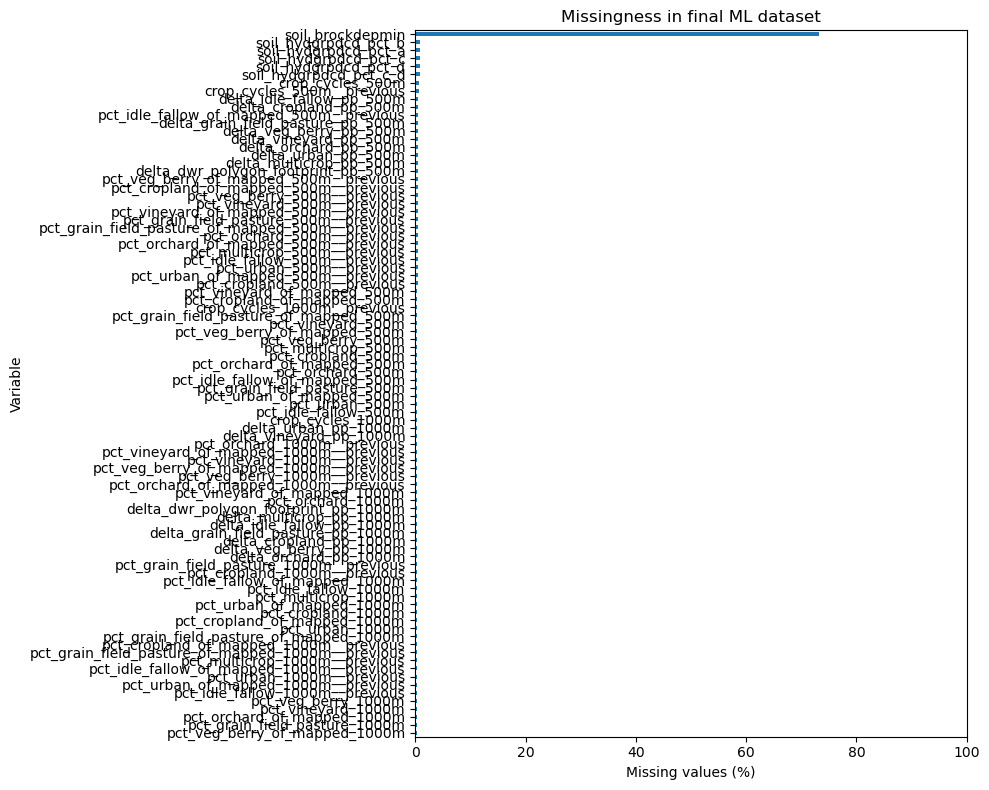

In [9]:
import matplotlib.pyplot as plt

missing_pct = (
    integrated.isna().mean()
    .mul(100)
    .sort_values(ascending=True)
)

# Show only variables that actually have missing values
missing_pct = missing_pct[missing_pct > 0]

plt.figure(figsize=(10, 8))
missing_pct.plot(kind="barh")

plt.xlabel("Missing values (%)")
plt.ylabel("Variable")
plt.title("Missingness in final ML dataset")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

## 7. Conclusions

- The integrated table has **5,280 nitrate observations from 1,993 wells and 147 columns** (2022: 1,455; 2023: 1,298; 2024: 1,252; 2025: 1,275 samples).
- Every observation was preserved through all joins, and **all 5,280 observations matched a historical crop record** (lag-1, 2021–2024 crop maps).
- The six PRISM climate features have **no missing values**.
- Missing values are rare except for **depth to bedrock (`soil_brockdepmin`, 73% missing)**, which is screened out in `notebooks/feature_selection.ipynb`.
- **Distance to large rivers** was not included because NHD stream-order data were unavailable.

**Assumptions and limitations**
- The one-year crop lag is a consistent modeling assumption, not an established nitrate transport time.
- The 2024 DWR crop map is provisional; it feeds the 2025 nitrate samples.
- Areas outside DWR-mapped polygons are not treated as zero agriculture; their share is kept as `outside_dwr_polygons_pct`.